# 🩺 Disease Prediction from Medical Data — CodeAlpha ML Internship (Task 4)

**Objective:** predict the possibility of disease from structured patient data (age, symptoms, blood tests).

| Dataset | Kaggle input |
|---|---|
| Heart disease (UCI) | [redwankarimsony/heart-disease-data](https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data) |
| Diabetes (Pima) | [uciml/pima-indians-diabetes-database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database) |
| Breast cancer (UCI Wisconsin) | built into scikit-learn |

**Algorithms:** SVM · Logistic Regression · Random Forest · XGBoost


## 1. Setup — imports & settings
Edit `DATASETS` if you did not attach one of the inputs.

In [1]:
import glob, json, os, warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
DATASETS = ["heart", "diabetes", "breast_cancer"]          # remove any you did not add as input
INPUT = "/kaggle/input" if os.path.exists("/kaggle/input") else "."
OUT_ROOT = "/kaggle/working/outputs" if os.path.exists("/kaggle/working") else "outputs"

## 2. Data loaders
- **Heart:** target `num` > 0 → disease; text/coded categories (chest-pain type, ECG, slope, thal) are one-hot encoded.
- **Diabetes:** zeros in Glucose, BloodPressure, SkinThickness, Insulin, BMI are impossible → treated as missing.
- **Breast cancer:** built into scikit-learn; malignant = positive class.

In [2]:
def find_csv(must_have_any):
    """Find the first CSV under /kaggle/input whose columns contain one of the given names."""
    for f in glob.glob(f"{INPUT}/**/*.csv", recursive=True):
        cols = pd.read_csv(f, nrows=2).columns
        if any(c in cols for c in must_have_any):
            print("Using:", f)
            return pd.read_csv(f)
    return None


def load_heart():
    df = find_csv(["num", "condition", "target", "output"])
    if df is None:
        raise FileNotFoundError("Add a UCI heart-disease CSV as input")
    df = df.drop_duplicates()                                # some Kaggle copies contain duplicate rows
    target = next(c for c in ["num", "condition", "target", "output"] if c in df.columns)
    y = (df.pop(target) > 0).astype(int)                     # 0 = healthy, >0 = disease
    X = df.drop(columns=[c for c in ["id", "dataset"] if c in df.columns])
    for c in X.columns:
        if X[c].dtype == bool:
            X[c] = X[c].astype(int)
    categorical = [c for c in X.columns
                   if not pd.api.types.is_numeric_dtype(X[c]) or c in ("cp", "restecg", "slope", "thal")]
    for c in categorical:
        X[c] = X[c].astype(str).replace("nan", np.nan)
    return X, y, categorical, "Heart disease"


def load_diabetes():
    df = find_csv(["Outcome"])                               # Kaggle uciml copy (has header)
    if df is None:                                           # other copies, e.g. pima-indians-diabetes.csv (no header)
        files = [f for f in glob.glob(f"{INPUT}/**/*.csv", recursive=True)
                 if "pima" in f.lower() or "diabetes" in os.path.basename(f).lower()]
        if files:
            print("Using:", files[0])
            df = pd.read_csv(files[0], header=None)
            if not str(df.iloc[0, 0]).replace(".", "").isdigit():   # first row is a header -> drop it
                df = df.iloc[1:].reset_index(drop=True)
            df = df.iloc[:, :9].astype(float)
            df.columns = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
                          "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
    if df is None:                                           # no CSV attached -> download from OpenML (Internet ON)
        from sklearn.datasets import fetch_openml
        ds = fetch_openml("diabetes", version=1, as_frame=True)
        df = ds.data.copy()
        df.columns = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
                      "BMI", "DiabetesPedigreeFunction", "Age"]
        df["Outcome"] = (ds.target == "tested_positive").astype(int)
        print("Using: OpenML Pima Indians Diabetes (id 37)")
    y = df.pop("Outcome").astype(int)
    for c in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]:
        df[c] = df[c].replace(0, np.nan)                     # impossible zeros = missing values
    return df, y, [], "Diabetes"


def load_bc():
    df = find_csv(["diagnosis"])                             # Kaggle uciml/breast-cancer-wisconsin-data
    if df is not None:
        y = (df.pop("diagnosis") == "M").astype(int)         # 1 = malignant
        X = df.drop(columns=[c for c in df.columns if c == "id" or c.startswith("Unnamed")])
        return X, y, [], "Breast cancer (malignant)"
    ds = load_breast_cancer(as_frame=True)                   # fallback: copy bundled with scikit-learn
    return ds.data, (ds.target == 0).astype(int), [], "Breast cancer (malignant)"


LOADERS = {"heart": load_heart, "diabetes": load_diabetes, "breast_cancer": load_bc}

## 3. Experiment pipeline
For each dataset: imputation → scaling → one-hot (inside a Pipeline, so no leakage) → **SVM, Logistic Regression, Random Forest, XGBoost**, each tuned with `GridSearchCV` (5-fold, ROC-AUC). The model is selected by CV score; the 20 % hold-out test set gives the final honest estimate. In medicine a missed patient is the costly error, so **Recall** is reported next to accuracy.

In [3]:
def run(name):
    out = f"{OUT_ROOT}/{name}"
    os.makedirs(out, exist_ok=True)
    X, y, categorical, label = LOADERS[name]()
    print(f"\n{'=' * 75}\n{label}: {len(X)} patients, {X.shape[1]} features, positive {y.mean():.1%}, "
          f"missing values {int(X.isna().sum().sum())}\n{'=' * 75}")

    numeric = [c for c in X.columns if c not in categorical]
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), numeric),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), categorical)])

    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    pos_w = float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))
    grid = {
        "Logistic Regression": (LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED),
                                {"clf__C": [0.01, 0.1, 1, 10]}),
        "SVM": (SVC(probability=True, class_weight="balanced", random_state=SEED),
                {"clf__C": [0.1, 1, 10], "clf__kernel": ["rbf", "linear"], "clf__gamma": ["scale", 0.01]}),
        "Random Forest": (RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED),
                          {"clf__n_estimators": [200, 400], "clf__max_depth": [4, 8, None],
                           "clf__min_samples_leaf": [1, 3, 5]}),
        "XGBoost": (XGBClassifier(eval_metric="logloss", scale_pos_weight=pos_w, n_jobs=-1, random_state=SEED),
                    {"clf__n_estimators": [200, 400], "clf__max_depth": [2, 3, 4],
                     "clf__learning_rate": [0.03, 0.1], "clf__subsample": [0.8, 1.0]}),
    }

    results, fitted, probas = {}, {}, {}
    for m, (clf, params) in grid.items():
        gs = GridSearchCV(Pipeline([("pre", pre), ("clf", clf)]), params, scoring="roc_auc", cv=cv, n_jobs=-1)
        gs.fit(X_tr, y_tr)
        fitted[m], probas[m] = gs.best_estimator_, gs.predict_proba(X_te)[:, 1]
        pred = (probas[m] >= 0.5).astype(int)
        results[m] = {"cv_roc_auc": round(gs.best_score_, 4), "accuracy": round(accuracy_score(y_te, pred), 4),
                      "precision": round(precision_score(y_te, pred, zero_division=0), 4),
                      "recall": round(recall_score(y_te, pred), 4), "f1": round(f1_score(y_te, pred), 4),
                      "roc_auc": round(roc_auc_score(y_te, probas[m]), 4)}
        print(f"  {m:20s} " + "  ".join(f"{k}={v:.3f}" for k, v in results[m].items()))

    best = max(results, key=lambda k: results[k]["cv_roc_auc"])          # selected on CV, not on test
    pred = (probas[best] >= 0.5).astype(int)
    print(f"\nSelected model (by CV AUC): {best}")
    print(classification_report(y_te, pred, target_names=["Healthy", "Disease"]))

    plt.figure(figsize=(6, 5))
    for m, p in probas.items():
        fpr, tpr, _ = roc_curve(y_te, p)
        plt.plot(fpr, tpr, label=f"{m} (AUC={roc_auc_score(y_te, p):.3f})")
    plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate"); plt.ylabel("Sensitivity")
    plt.title(f"{label} - ROC"); plt.legend(); plt.tight_layout(); plt.savefig(f"{out}/roc_curves.png", dpi=150); plt.show()

    ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Healthy", "Disease"]).plot(cmap="Reds")
    plt.title(f"{label} - {best}"); plt.tight_layout(); plt.savefig(f"{out}/confusion_matrix.png", dpi=150); plt.show()

    pi = permutation_importance(fitted[best], X_te, y_te, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=-1)
    pd.Series(pi.importances_mean, index=X.columns).sort_values().tail(12).plot.barh(
        figsize=(7, 5), title=f"{label} - permutation importance ({best})")
    plt.tight_layout(); plt.savefig(f"{out}/feature_importance.png", dpi=150); plt.show()

    pd.DataFrame(results).T.to_csv(f"{out}/model_comparison.csv")
    json.dump({"dataset": label, "selected_model": best, "results": results}, open(f"{out}/metrics.json", "w"), indent=2)
    joblib.dump(fitted[best], f"{out}/{name}_model.joblib")
    return label, best, results[best]

## 4. Heart disease

Using: /kaggle/input/datasets/redwankarimsony/heart-disease-data/heart_disease_uci.csv

Heart disease: 920 patients, 13 features, positive 55.3%, missing values 1759
  Logistic Regression  cv_roc_auc=0.887  accuracy=0.837  precision=0.846  recall=0.863  f1=0.854  roc_auc=0.902
  SVM                  cv_roc_auc=0.892  accuracy=0.848  precision=0.825  recall=0.922  f1=0.870  roc_auc=0.916
  Random Forest        cv_roc_auc=0.886  accuracy=0.859  precision=0.865  recall=0.882  f1=0.874  roc_auc=0.929
  XGBoost              cv_roc_auc=0.883  accuracy=0.853  precision=0.864  recall=0.873  f1=0.868  roc_auc=0.927

Selected model (by CV AUC): SVM
              precision    recall  f1-score   support

     Healthy       0.89      0.76      0.82        82
     Disease       0.82      0.92      0.87       102

    accuracy                           0.85       184
   macro avg       0.86      0.84      0.84       184
weighted avg       0.85      0.85      0.85       184



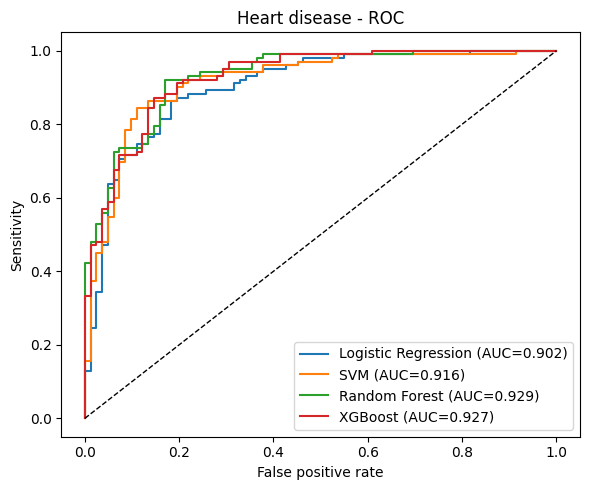

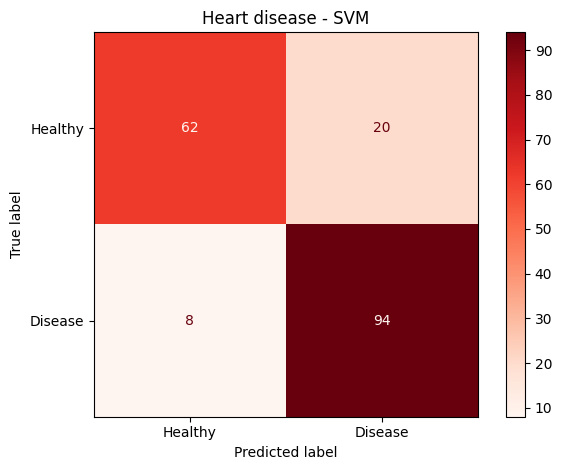

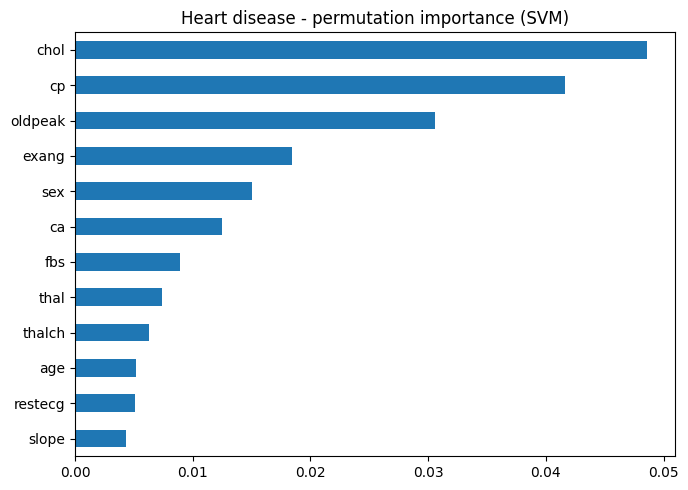

In [4]:
heart = run("heart")

## 5. Diabetes

Using: /kaggle/input/datasets/kumargh/pimaindiansdiabetescsv/pima-indians-diabetes.csv

Diabetes: 768 patients, 8 features, positive 34.9%, missing values 652
  Logistic Regression  cv_roc_auc=0.845  accuracy=0.708  precision=0.571  recall=0.667  f1=0.615  roc_auc=0.810
  SVM                  cv_roc_auc=0.849  accuracy=0.708  precision=0.600  recall=0.500  f1=0.545  roc_auc=0.810
  Random Forest        cv_roc_auc=0.842  accuracy=0.747  precision=0.615  recall=0.741  f1=0.672  roc_auc=0.821
  XGBoost              cv_roc_auc=0.837  accuracy=0.740  precision=0.600  recall=0.778  f1=0.677  roc_auc=0.824

Selected model (by CV AUC): SVM
              precision    recall  f1-score   support

     Healthy       0.75      0.82      0.78       100
     Disease       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



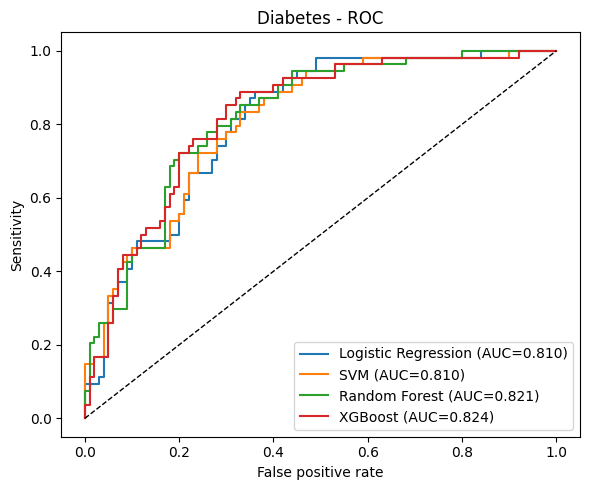

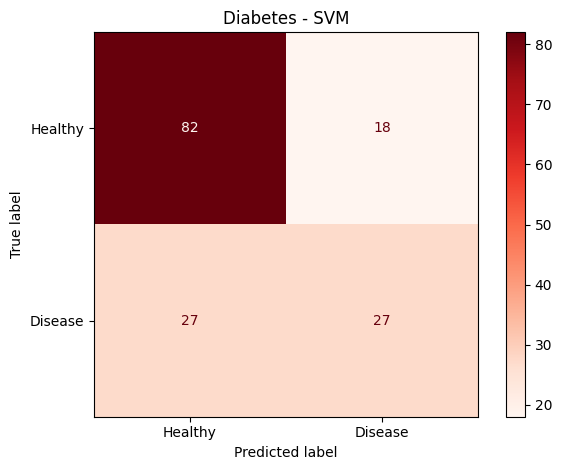

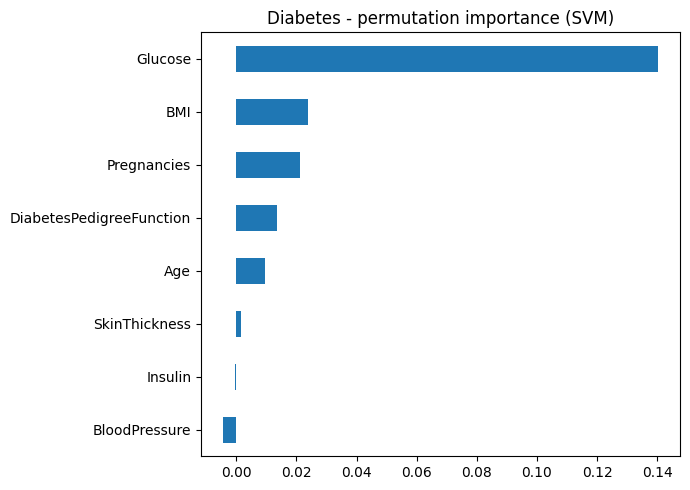

In [5]:
diabetes = run("diabetes")

## 6. Breast cancer

Using: /kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv

Breast cancer (malignant): 569 patients, 30 features, positive 37.3%, missing values 0
  Logistic Regression  cv_roc_auc=0.995  accuracy=0.974  precision=0.976  recall=0.952  f1=0.964  roc_auc=0.995
  SVM                  cv_roc_auc=0.996  accuracy=0.983  precision=1.000  recall=0.952  f1=0.976  roc_auc=0.997
  Random Forest        cv_roc_auc=0.989  accuracy=0.974  precision=1.000  recall=0.929  f1=0.963  roc_auc=0.996
  XGBoost              cv_roc_auc=0.995  accuracy=0.974  precision=1.000  recall=0.929  f1=0.963  roc_auc=0.991

Selected model (by CV AUC): SVM
              precision    recall  f1-score   support

     Healthy       0.97      1.00      0.99        72
     Disease       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



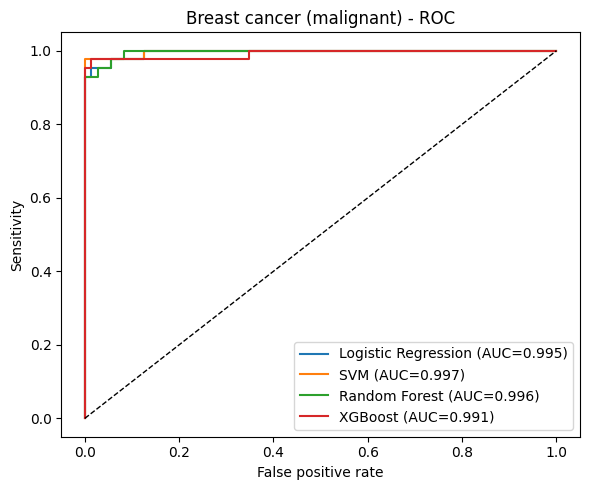

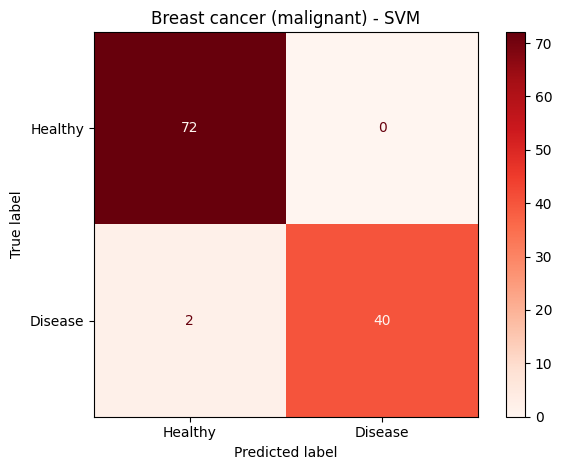

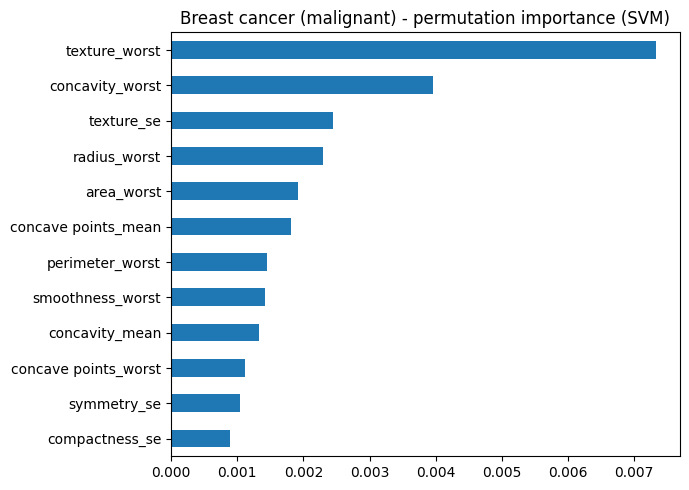

In [6]:
breast = run("breast_cancer")

## 7. Summary (hold-out test set)

In [7]:
import pandas as pd
summary = pd.DataFrame({lbl: {"model": m, **r} for lbl, m, r in [heart, diabetes, breast]}).T
summary[["model", "accuracy", "precision", "recall", "f1", "roc_auc"]]

,model,accuracy,precision,recall,f1,roc_auc
Heart disease,SVM,0.8478,0.8246,0.9216,0.8704,0.9163
Diabetes,SVM,0.7078,0.6,0.5,0.5455,0.8096
Breast cancer (malignant),SVM,0.9825,1.0,0.9524,0.9756,0.997
